# Olist marketplace: why customers don't come back, and what to fix first

**Business question.** Olist is a Brazilian marketplace connecting small sellers to customers.
Leadership believes *bad delivery experiences are killing repeat purchases*. Is that true?
And if not, where should the business spend its effort?

**Data.** Olist's public dataset: 99,441 orders, 9 relational tables, Sep 2016 to Oct 2018.
The analysis covers the **96,470 delivered orders** from **93,350 unique customers**.

**Approach.**
1. SQL (DuckDB) builds a clean order-level fact table and a customer dimension (`sql/01_build_model.sql`)
2. SQL answers each business question (`sql/02` to `07`), saved to `data/processed/`
3. This notebook adds statistical tests, impact sizing and the recommendations

> **Spoiler.** The hypothesis is only half right. Late delivery strongly damages **ratings**,
> but it does **not** measurably reduce **repeat purchases**. Repeat buying is ~2% no matter
> what happens. So the fixes are two separate programmes: an operations fix for lateness
> and a CRM fix for retention.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import run_sql, charts
run_sql.main()            # rebuild the model and every SQL output from the raw CSVs
charts.build_all()        # re-render every figure

P = ROOT / "data" / "processed"
read = lambda name: pd.read_csv(P / f"{name}.csv")
fig = lambda name: display(Image(filename=str(ROOT / "reports" / "figures" / f"{name}.png"), width=760))
pd.set_option("display.float_format", "{:,.2f}".format)

loading raw CSVs ...


building model (01_build_model.sql) ...


  02_data_quality.sql          -> dq_row_counts.csv (9 rows)
  02_data_quality.sql          -> dq_order_status.csv (8 rows)
  02_data_quality.sql          -> dq_issues.csv (7 rows)
  03_kpi_overview.sql          -> kpi_headline.csv (1 rows)
  03_kpi_overview.sql          -> kpi_monthly.csv (20 rows)
  04_delivery_and_reviews.sql  -> reviews_by_delivery_status.csv (2 rows)
  04_delivery_and_reviews.sql  -> reviews_by_days_vs_promise.csv (6 rows)
  04_delivery_and_reviews.sql  -> negative_review_themes.csv (5 rows)
  05_retention.sql             -> retention_summary.csv (1 rows)


  05_retention.sql             -> days_to_second_purchase.csv (5 rows)
  05_retention.sql             -> repeat_by_first_order_experience.csv (2 rows)
  05_retention.sql             -> repeat_by_first_review.csv (3 rows)
  05_retention.sql             -> repeat_by_first_category.csv (17 rows)
  05_retention.sql             -> cohort_retention.csv (14 rows)
  06_sellers_and_routes.sql    -> seller_pareto.csv (2948 rows)
  06_sellers_and_routes.sql    -> seller_watchlist.csv (65 rows)
  06_sellers_and_routes.sql    -> route_performance.csv (27 rows)
  06_sellers_and_routes.sql    -> late_by_customer_state.csv (27 rows)


  07_customer_segments.sql     -> customer_segments.csv (6 rows)


  exported fact_orders.csv, dim_customers.csv


## 1. Data quality: what had to be fixed before trusting any number

In [2]:
display(read("dq_row_counts")); display(read("dq_issues"))

,table_name,n_rows
0,raw_orders,99441
1,raw_customers,99441
2,raw_items,112650
3,raw_payments,103886
4,raw_reviews,99224
5,raw_products,32951
6,raw_sellers,3095
7,fact_orders (delivered),96470
8,dim_customers (people),93350


,issue,affected_rows,handling
0,"customer_id is per ORDER, not per person",3345,use customer_unique_id as the real customer key
1,orders with more than one review,547,average the scores
2,delivered orders missing delivery date,8,excluded from fact_orders
3,delivered orders without a review,646,kept; excluded only from rating metrics
4,orders with more than one seller,1275,excluded from seller-level metrics only
5,"same-day ""repeat"" orders (split baskets)",890,repeat customer = purchases on 2+ different days
6,"sparse months (2016-09..12, 2018-09..10)",349,excluded from monthly trend charts


The two decisions that matter most:
* **`customer_unique_id` is the real person.** The raw `customer_id` changes with every order, so using it
  would make the repeat rate look like 0%.
* **Same-day orders are not loyalty.** 890 extra orders were placed on the same day as an earlier one
  (one basket split by seller). A *repeat customer* is someone who bought on **two different days**.

## 2. Headline KPIs

In [3]:
read("kpi_headline").T.rename(columns={0: "value"})

,value
delivered_orders,"96,470.00"
customers,"93,350.00"
sellers,"2,959.00"
revenue_brl,"15,421,083.00"
avg_order_value_brl,159.86
avg_review_score,4.16
late_rate_pct,8.11
avg_delivery_days,12.50
median_days_vs_promise,-12.00
repeat_customer_pct,2.16


* R$15.4M revenue, average order R$160, average rating 4.16 / 5
* **8.1% of orders arrive after the promised date**, even though the median order arrives **12 days early**
  (the promised dates are already generous)
* **Only 2.16% of customers ever buy a second time**, and they generate just 4.2% of revenue

## 3. Does late delivery hurt customer satisfaction?

,delivery_status,orders,pct_of_orders,avg_review,negative_review_pct,negative_reviews,pct_of_all_negative_reviews
0,Late,7661,8.00,2.57,54.00,"4,136.00",33.80
1,On time / early,88163,92.00,4.29,9.20,"8,100.00",66.20


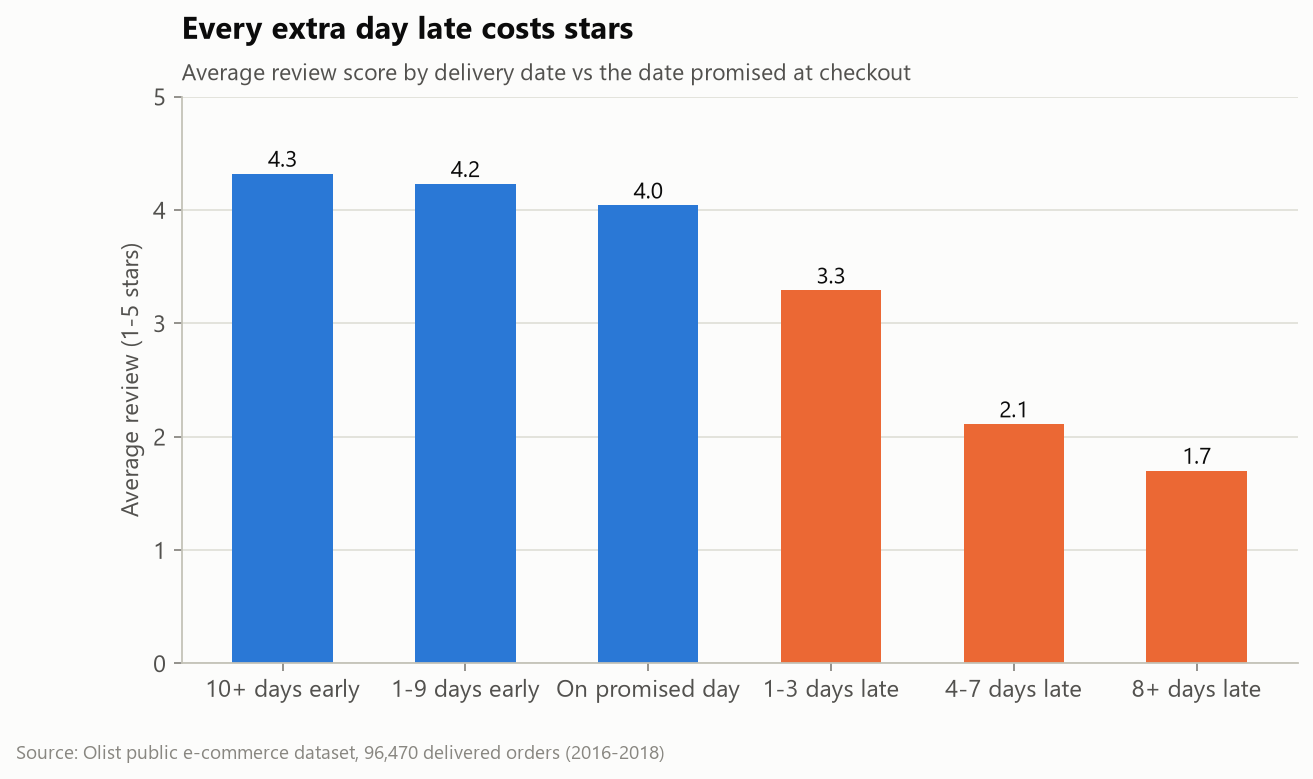

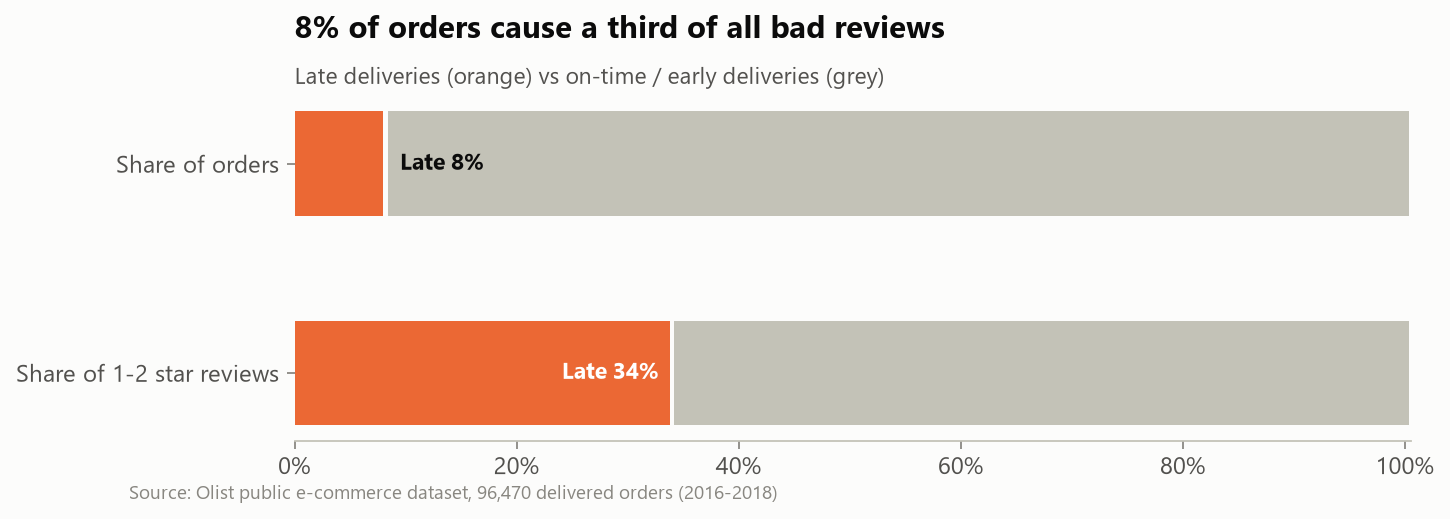

In [4]:
display(read("reviews_by_delivery_status")); fig("fig01_reviews_by_delay"); fig("fig02_negative_review_share")

In [5]:
f = pd.read_csv(P / "fact_orders.csv", usecols=["is_late", "review_score", "is_negative_review"]).dropna()
late, ontime = f[f.is_late == 1].review_score, f[f.is_late == 0].review_score
u = stats.mannwhitneyu(late, ontime)
neg_late, neg_on = f[f.is_late == 1].is_negative_review.mean(), f[f.is_late == 0].is_negative_review.mean()
excess_neg = (neg_late - neg_on) * (f.is_late == 1).sum()
print(f"Mann-Whitney U test, late vs on-time review scores: p {'< 0.001' if u.pvalue < 0.001 else f'= {u.pvalue:.3f}'}")
print(f"Negative-review rate: late {neg_late:.1%} vs on-time {neg_on:.1%}  ({neg_late/neg_on:.1f}x)")
print(f"Bad reviews attributable to lateness: ~{excess_neg:,.0f} = {excess_neg / f.is_negative_review.sum():.0%} of all 1-2 star reviews")

Mann-Whitney U test, late vs on-time review scores: p < 0.001
Negative-review rate: late 54.0% vs on-time 9.2%  (5.9x)
Bad reviews attributable to lateness: ~3,432 = 28% of all 1-2 star reviews


In [6]:
read("negative_review_themes")

,theme,reviews_mentioning,pct_of_negative_comments
0,Delivery / not received / delay,5923,64.30
1,Damaged / defective / poor quality,907,9.80
2,Partial order (missing items),884,9.60
3,Wrong / different product,762,8.30
4,Refund / cancellation,553,6.00


**Finding 1: lateness is the #1 driver of bad reviews.**
Late orders are 8% of volume but 34% of all 1-2 star reviews. The damage grows with every day of delay
(4.0 stars on the promised day, 3.3 at 1-3 days late, 1.7 at 8+ days late). About 64% of negative
comments mention delivery ("não recebi" = *I didn't receive it*, "atraso" = *delay*).

## 4. Where and when does lateness happen?

3 peak months = 22% of orders but 46% of late deliveries


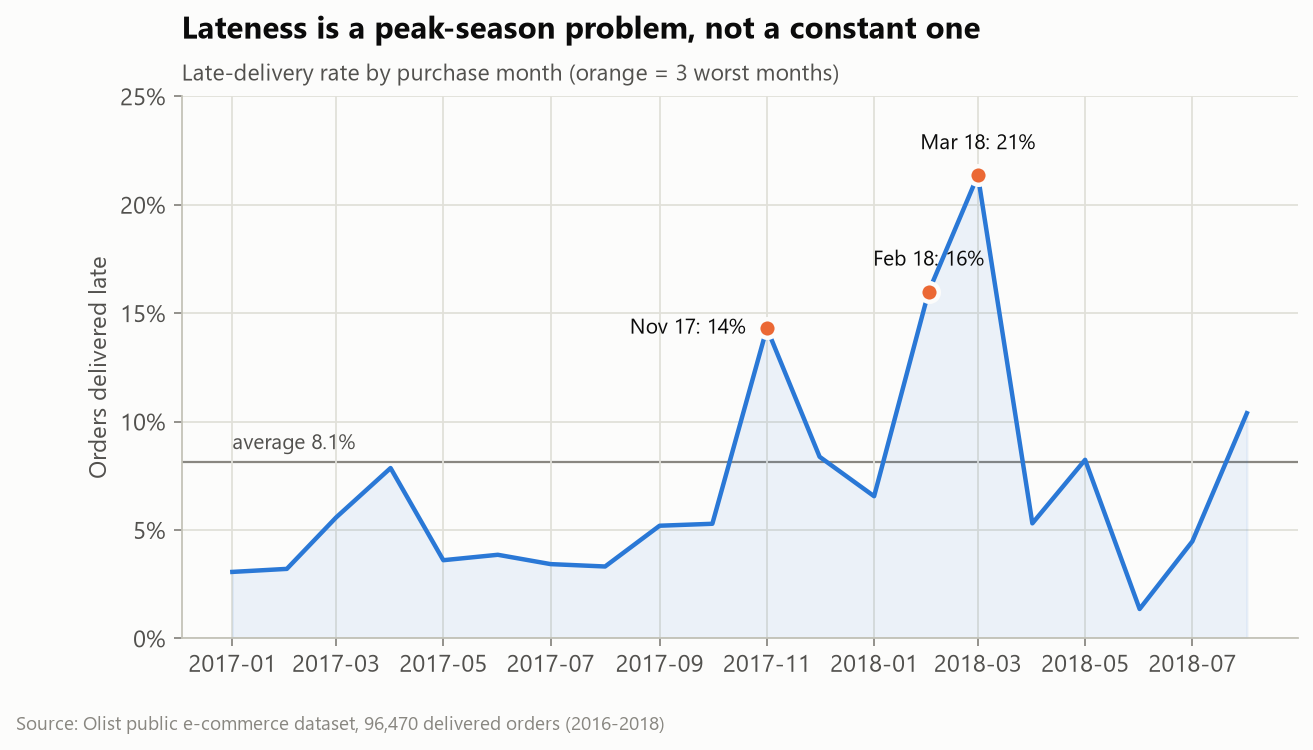

In [7]:
m = read("kpi_monthly"); m["month"] = pd.to_datetime(m.purchase_month).dt.strftime("%Y-%m")
m["late_orders"] = (m.orders * m.late_rate_pct / 100).round()
peak = m[m.month.isin(["2017-11", "2018-02", "2018-03"])]
print(f"3 peak months = {peak.orders.sum() / m.orders.sum():.0%} of orders but "
      f"{peak.late_orders.sum() / m.late_orders.sum():.0%} of late deliveries")
fig("fig03_monthly_late_rate")

 102 sellers (3.5% of sellers) cause 50% of late orders
 423 sellers (14.3% of sellers) cause 80% of late orders
Chronic-late watchlist: 65 sellers (30+ orders, >=15% late) | 5,001 orders | 968 late


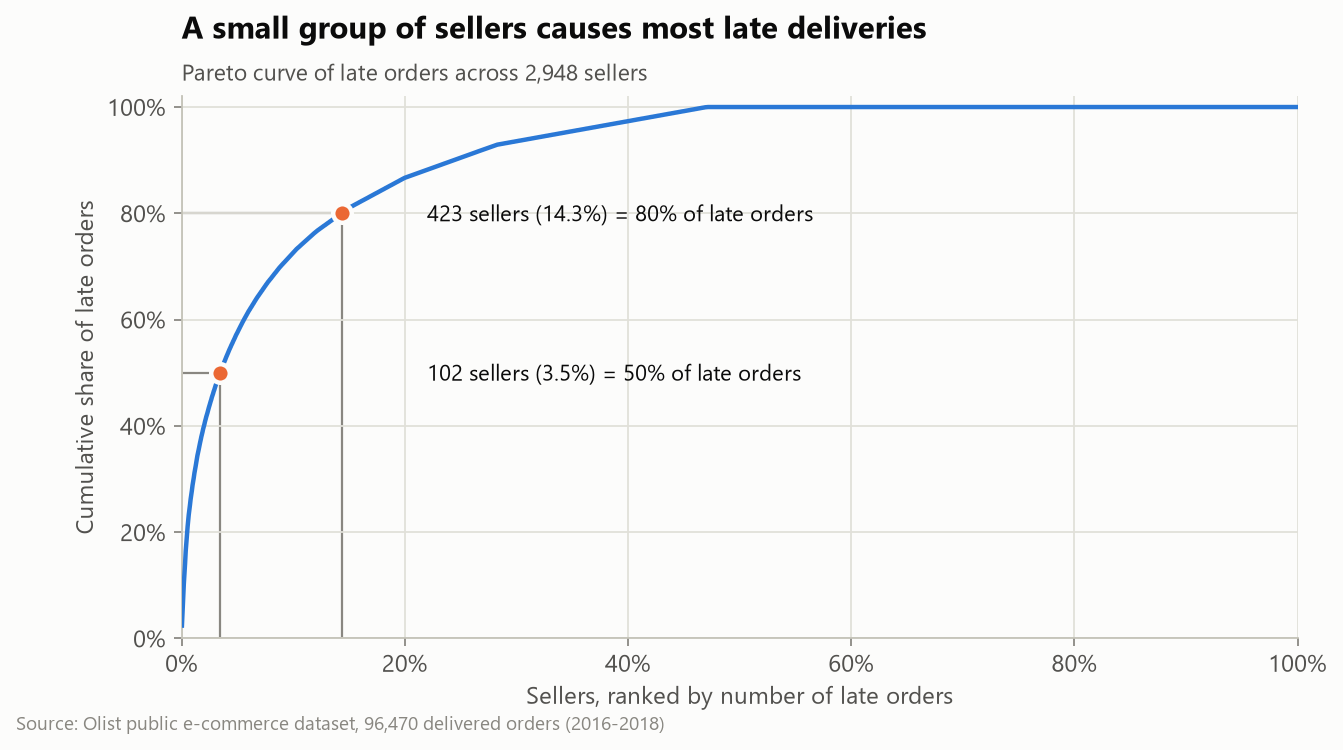

In [8]:
p = read("seller_pareto")
for t in (50, 80):
    r = p[p.cum_pct_of_late_orders >= t].iloc[0]
    print(f"{int(r.seller_rank):>4} sellers ({r.pct_of_sellers:.1f}% of sellers) cause {t}% of late orders")
w = read("seller_watchlist")
print(f"Chronic-late watchlist: {len(w)} sellers (30+ orders, >=15% late) | {w.orders.sum():,} orders | {w.late_orders.sum():,.0f} late")
fig("fig04_seller_pareto")

,route,orders,late_orders,late_rate_pct,avg_delivery_days,avg_review,pct_of_all_late
0,SP -> SP,30313,"1,907.00",6.30,7.90,4.26,24.40
1,SP -> RJ,8048,"1,258.00",15.60,16.30,3.90,16.10
2,SP -> MG,7326,470.00,6.40,12.30,4.17,6.00
3,SP -> BA,2278,345.00,15.10,19.80,3.89,4.40
4,SP -> RS,3540,273.00,7.70,16.20,4.14,3.50
5,SP -> SC,2306,256.00,11.10,15.80,4.05,3.30
6,SP -> ES,1444,206.00,14.30,15.80,4.06,2.60
7,SP -> PR,3077,167.00,5.40,12.80,4.21,2.10
8,SP -> CE,961,148.00,15.40,21.20,3.97,1.90
9,PR -> RJ,951,135.00,14.20,17.30,3.91,1.70


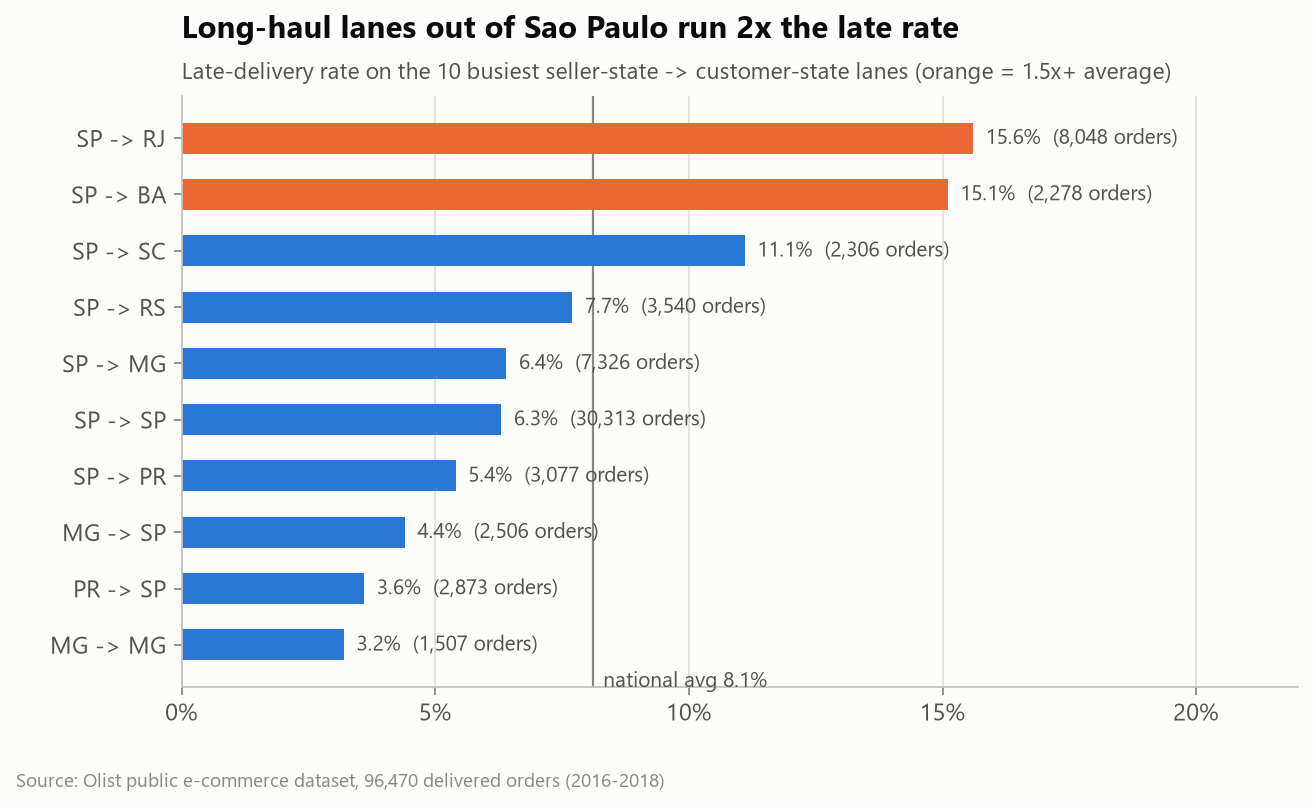

In [9]:
display(read("route_performance").head(10)); fig("fig05_routes")

**Finding 2: lateness is concentrated, so it is fixable.**
* **Time:** three months (Nov 2017 Black Friday, Feb and Mar 2018) carry nearly half of all late deliveries.
  That is a capacity-planning failure in peaks, not a constant problem.
* **Sellers:** 3.5% of sellers cause half of all late orders.
* **Lanes:** long-haul lanes out of São Paulo (SP→RJ, SP→BA, SP→ES, SP→CE) run ~15% late, 2x the
  average. SP→RJ alone produces 16% of all late orders. The promised date doesn't adjust enough for distance.

## 5. Does a bad experience stop customers coming back?

Repeat within 180 days, overall: 1.98%  (n = 55,523)
  first order on time: 2.01% came back (n = 51,257)
  first order late   : 1.69% came back (n = 4,266)
chi-square p (late vs on-time):     0.17  -> not significant
chi-square p (first rating band):   0.13  -> not significant


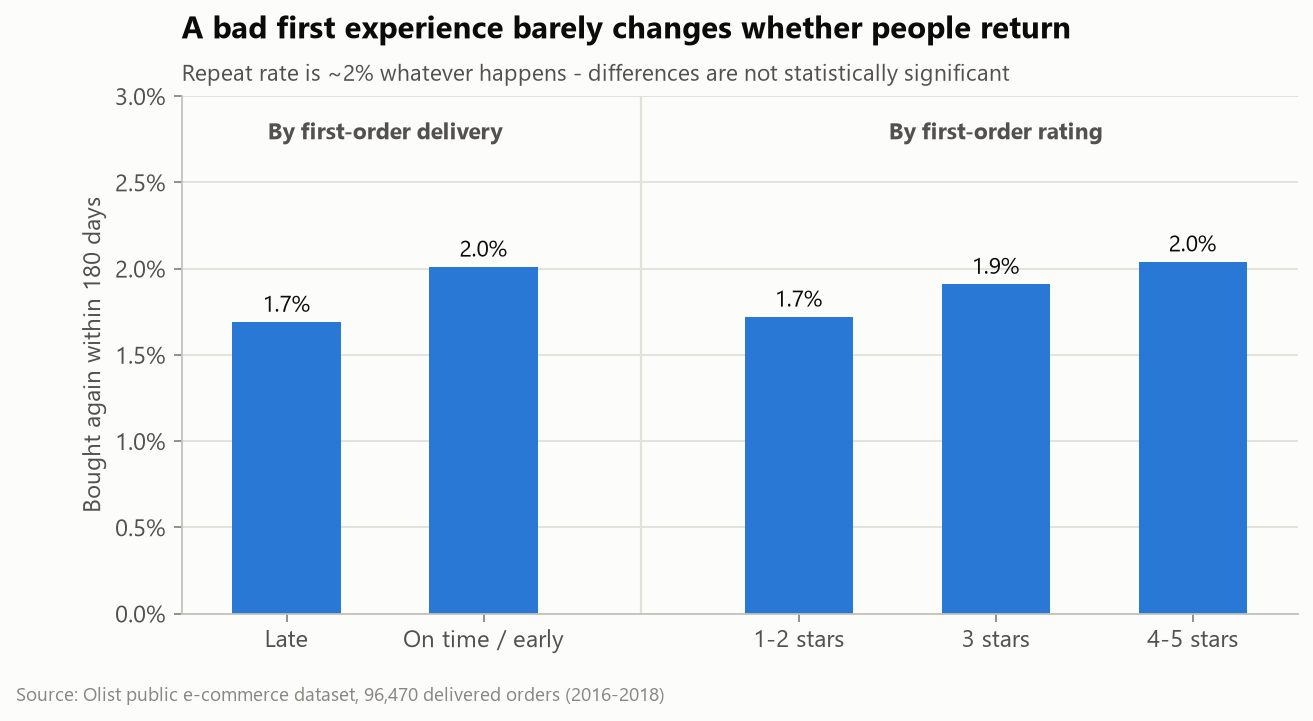

In [10]:
c = pd.read_csv(P / "dim_customers.csv", parse_dates=["first_purchase_date"])
cw = c[c.first_purchase_date < "2018-03-01"].copy()      # everyone gets a full 180-day window

def chi(col):
    t = pd.crosstab(cw[col], cw.repeat_180d)
    return stats.chi2_contingency(t)[1]

cw["rating_band"] = pd.cut(cw.first_order_review, [0, 2, 3, 5], labels=["1-2", "3", "4-5"])
print(f"Repeat within 180 days, overall: {cw.repeat_180d.mean():.2%}  (n = {len(cw):,})")
for flag, g in cw.groupby("first_order_late"):
    print(f"  first order {'late   ' if flag else 'on time'}: {g.repeat_180d.mean():.2%} came back (n = {len(g):,})")
print(f"chi-square p (late vs on-time):     {chi('first_order_late'):.2f}  -> not significant")
print(f"chi-square p (first rating band):   {chi('rating_band'):.2f}  -> not significant")
fig("fig06_repeat_vs_experience")

**Finding 3: the hypothesis is wrong.** Customers whose first order was late come back at 1.7% vs 2.0%;
1-star customers at 1.7% vs 2.0% for 5-star customers. Neither difference is statistically significant.
**Fixing delivery will improve ratings, but on its own it will not create repeat customers.**

So what *does* relate to repeat buying?

chi-square p (first-order category): < 0.001  -> significant


,category,customers,came_back_180d,repeat_180d_pct
0,fashion_bags_accessories,1138,38.00,3.34
1,bed_bath_table,5372,145.00,2.70
2,sports_leisure,4499,119.00,2.65
3,furniture_decor,3720,89.00,2.39
4,garden_tools,2300,49.00,2.13
5,perfumery,1973,41.00,2.08


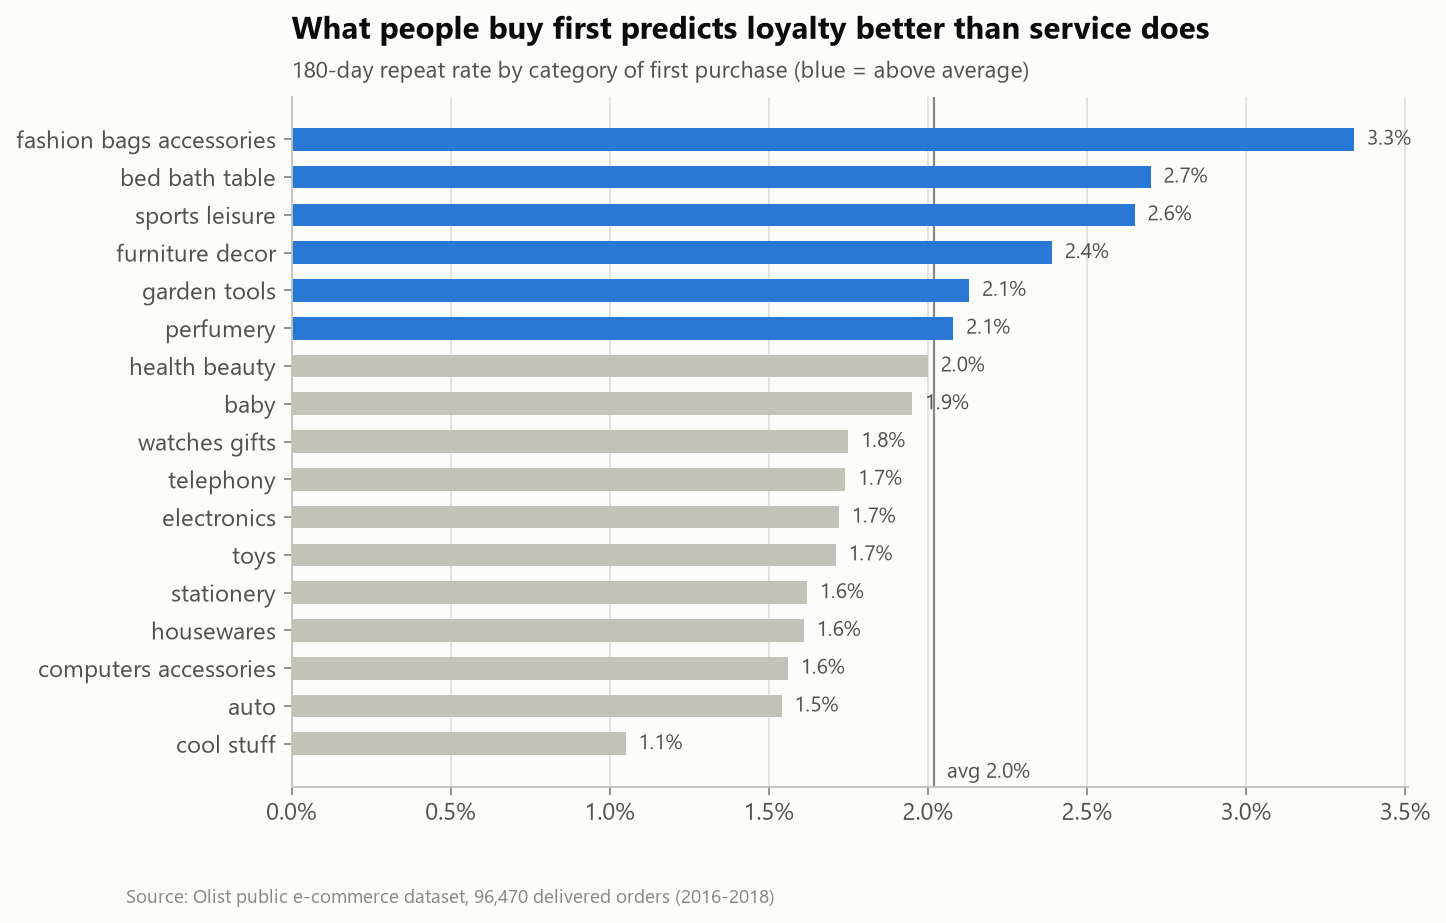

In [11]:
top = cw.first_order_category.value_counts()
cats = cw[cw.first_order_category.isin(top[top >= 1000].index)]
p_cat = stats.chi2_contingency(pd.crosstab(cats.first_order_category, cats.repeat_180d))[1]
print(f"chi-square p (first-order category): {'< 0.001' if p_cat < 0.001 else round(p_cat, 3)}  -> significant")
display(read("repeat_by_first_category").head(6)); fig("fig07_repeat_by_category")

In [12]:
# Can we predict who comes back from first-order information? (honest check)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
X = pd.get_dummies(cw[["first_order_category", "customer_state", "first_payment_type"]].fillna("na"), drop_first=True)
X["late"] = cw.first_order_late; X["review"] = cw.first_order_review.fillna(cw.first_order_review.median())
X["log_value"] = np.log1p(cw.first_order_value.fillna(0))
auc = cross_val_score(LogisticRegression(max_iter=2000, class_weight="balanced"), X, cw.repeat_180d, cv=5, scoring="roc_auc")
print(f"5-fold ROC-AUC predicting repeat from first-order data: {auc.mean():.3f} (0.5 = coin flip)")

5-fold ROC-AUC predicting repeat from first-order data: 0.544 (0.5 = coin flip)


**Finding 4: repeat buying is not something customers drift into; it has to be triggered.**
First-purchase category matters (fashion accessories 3.3%, bed/bath 2.7% vs cool-stuff 1.1%, p < 0.001),
but even a model using every first-order attribute barely beats a coin flip. Nothing in the first
experience strongly predicts return, which points to the missing piece: **there is no retention
programme pulling customers back.** And timing is clear: 76% of those who do return do so within 6 months.

,gap_bucket,customers,pct,cumulative_pct
0,1. within 30 days,600,29.80,29.80
1,2. 31-90 days,507,25.20,54.90
2,3. 91-180 days,423,21.00,75.90
3,4. 181-365 days,401,19.90,95.80
4,5. over 1 year,84,4.20,100.00


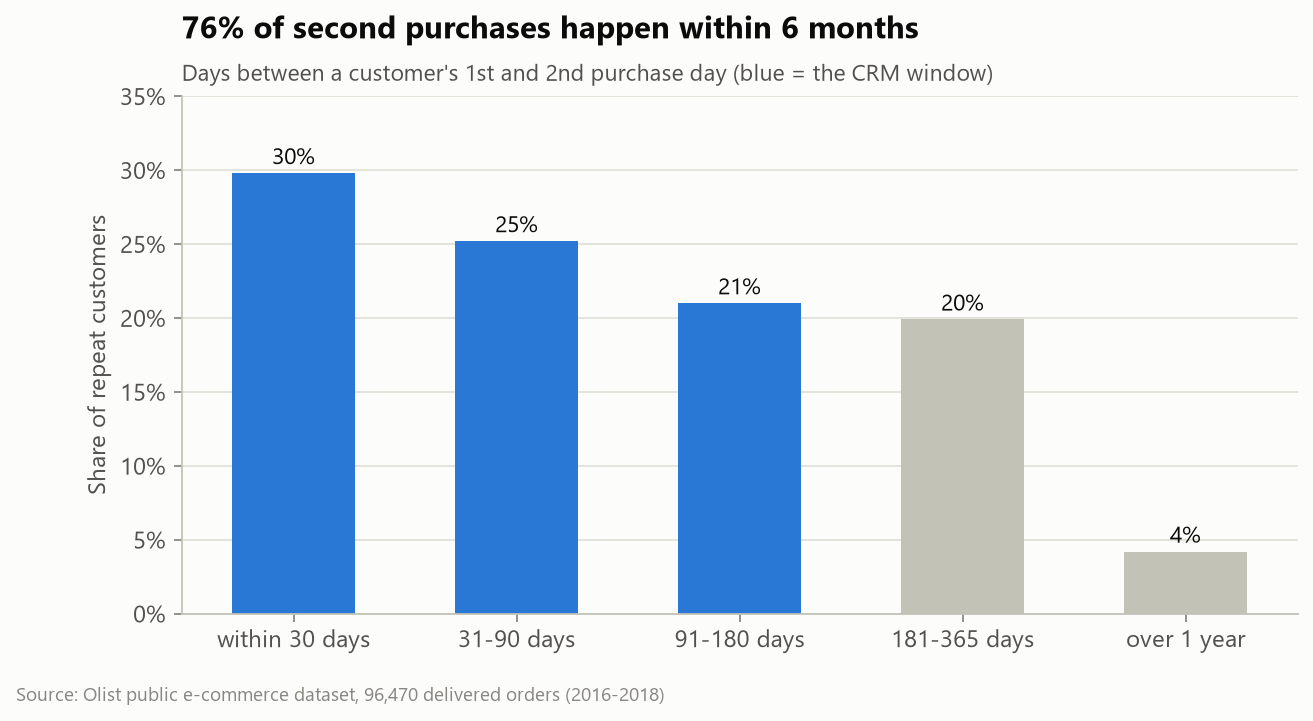

In [13]:
display(read("days_to_second_purchase")); fig("fig08_days_to_second")

## 6. Who to target

,segment,customers,pct_customers,revenue_brl,pct_revenue,avg_value_brl,avg_recency_days
0,"1. Loyal (repeat, active)",1076,1.20,"351,466.00",2.30,327.00,89.00
1,2. Lapsed repeat buyers,939,1.00,"294,988.00",1.90,314.00,311.00
2,3. New high-value (win 2nd order),5827,6.20,"2,320,877.00",15.10,398.00,62.00
3,4. New standard (win 2nd order),18188,19.50,"1,632,435.00",10.60,90.00,61.00
4,5. Dormant high-value,16169,17.30,"6,280,794.00",40.70,388.00,303.00
5,6. Dormant one-time,51151,54.80,"4,540,521.00",29.40,89.00,303.00


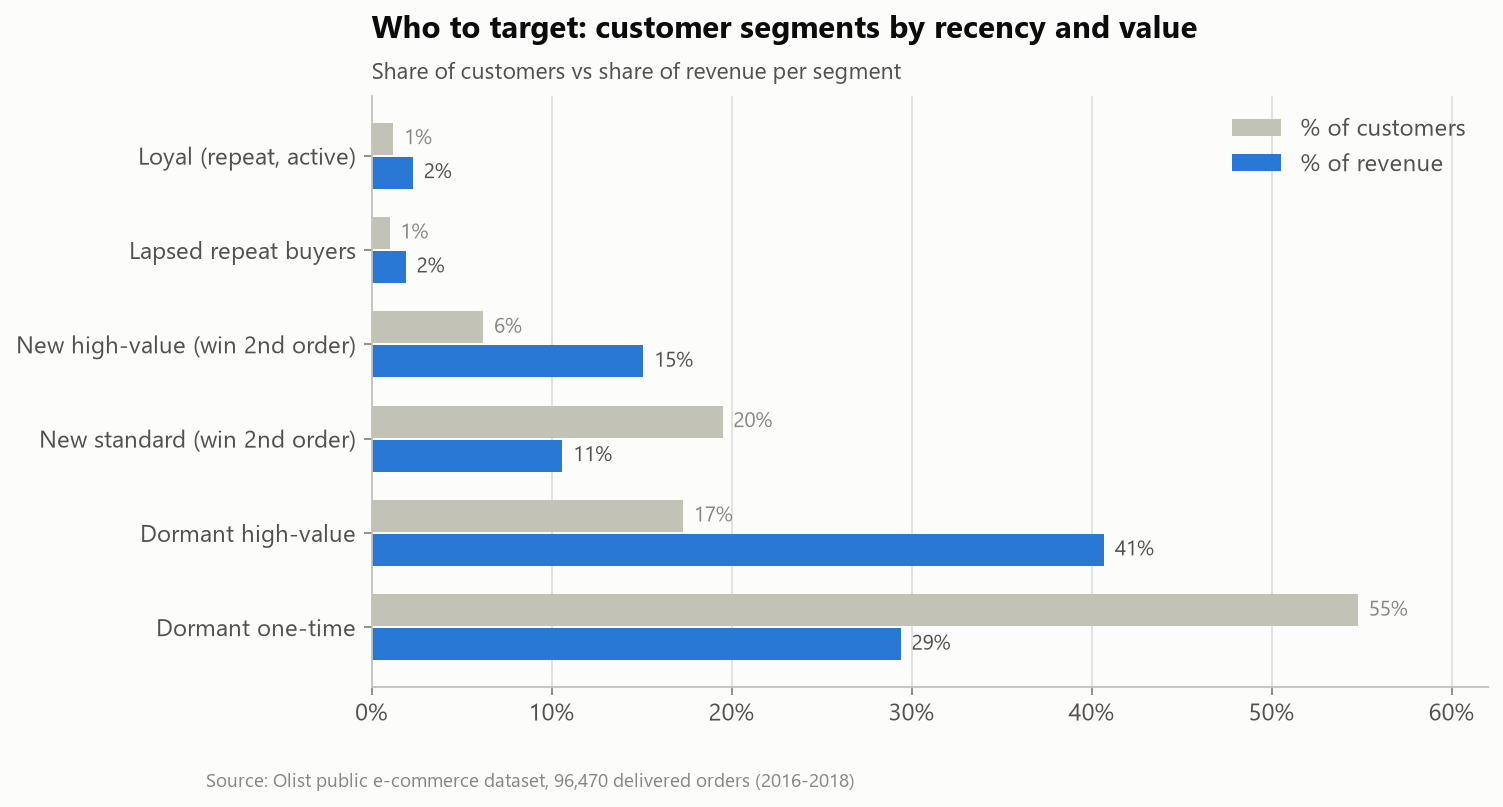

In [14]:
display(read("customer_segments")); fig("fig09_segments")

* **New customers (last 120 days): 24,000 people, 26% of revenue.** This is the best second-order audience; they are inside the window when returns happen.
* **Dormant high-value: 16,000 people (17%) who generated 41% of revenue.** This is the win-back audience.

## 7. Impact sizing (scenarios, with assumptions shown)

In [15]:
k = read("kpi_headline").iloc[0]; r = read("retention_summary").iloc[0]
st = read("reviews_by_delivery_status").set_index("delivery_status")
neg_gap = (st.loc["Late", "negative_review_pct"] - st.loc["On time / early", "negative_review_pct"]) / 100
avg_late = k.late_rate_pct / 100

# A. Bring high-risk lanes (>=1.5x average, 500+ orders) down to the national average
lanes = read("route_performance"); hot = lanes[lanes.late_rate_pct >= 150 * avg_late]
a_late = (hot.late_orders - hot.orders * avg_late).sum()
# B. Bring the chronic-late seller watchlist down to the national average
w = read("seller_watchlist"); b_late = (w.late_orders - w.orders * avg_late).sum()
# C. Bring the 3 peak months down to the average of the other months
off = m[~m.month.isin(peak.month)]; off_rate = off.late_orders.sum() / off.orders.sum()
c_late = (peak.late_orders - peak.orders * off_rate).sum()

ops = pd.DataFrame({
    "lever": [f"A. Fix {len(hot)} high-risk lanes", f"B. Seller SLA for {len(w)} chronic sellers", "C. Peak-season capacity plan"],
    "late_orders_avoided": [a_late, b_late, c_late]})
ops["pct_of_all_late"] = ops.late_orders_avoided / (k.delivered_orders * avg_late) * 100
ops["bad_reviews_avoided"] = ops.late_orders_avoided * neg_gap
display(ops.round(0))
print("Levers overlap (a late SP->RJ order in March from a watchlist seller counts in all three), so do not add them up.")

,lever,late_orders_avoided,pct_of_all_late,bad_reviews_avoided
0,A. Fix 6 high-risk lanes,"1,017.00",13.00,455.00
1,B. Seller SLA for 65 chronic sellers,562.00,7.00,252.00
2,C. Peak-season capacity plan,"2,415.00",31.00,"1,082.00"


Levers overlap (a late SP->RJ order in March from a watchlist seller counts in all three), so do not add them up.


In [16]:
# D. Retention: second-order CRM programme
new_per_year = c[(c.first_purchase_date >= "2018-01-01") & (c.first_purchase_date < "2018-09-01")].shape[0] / 8 * 12
extra_value = r.avg_ltv_repeat - r.avg_ltv_one_time      # what a converted repeat customer adds
annual_rev = k.revenue_brl / 20 * 12                      # ~20 months of data
crm = pd.DataFrame({"repeat_uplift_pp": [0.5, 1.0, 2.0]})
crm["extra_repeat_customers"] = new_per_year * crm.repeat_uplift_pp / 100
crm["extra_revenue_brl"] = crm.extra_repeat_customers * extra_value
crm["pct_of_annual_revenue"] = crm.extra_revenue_brl / annual_rev * 100
print(f"New customers per year ~{new_per_year:,.0f} | value added per converted repeat customer R${extra_value:,.0f} | annual revenue ~R${annual_rev/1e6:.1f}M")
display(crm.round(1))

New customers per year ~76,436 | value added per converted repeat customer R$159 | annual revenue ~R$9.3M


,repeat_uplift_pp,extra_repeat_customers,extra_revenue_brl,pct_of_annual_revenue
0,0.50,382.20,"60,789.20",0.70
1,1.00,764.40,"121,578.30",1.30
2,2.00,"1,528.70","243,156.60",2.60


Reading the scenarios honestly:
* **Operations levers** each remove roughly 7-31% of late orders and ~250 to ~1,100 bad reviews; the peak-season plan is the biggest single lever.
  Ratings are the marketplace's public reputation; the revenue effect via conversion can't be measured with
  this dataset and should be tracked after launch.
* **Retention**: +1 percentage point of repeat rate (2% → 3%, still below the 3.3% the best category
  already achieves organically) is worth about R$120K a year (~1.3% of revenue). That is modest per year but
  compounding, and cheap to test with email/app campaigns.

## 8. Recommendations

| # | Recommendation | Owner | Evidence | How to measure |
|---|---|---|---|---|
| 1 | **Peak-season playbook:** add carrier capacity and extend promised dates on long-haul lanes for Black Friday and Feb-Mar | Operations | 3 months = ~half of all late orders | Late rate in peak months ≤ 8% |
| 2 | **Lane-aware delivery promise** for SP→RJ/BA/ES/CE: set the promised date from each lane's actual history | Product / Logistics | Long-haul lanes 2x late; promise not adjusted enough for distance | Late rate per lane; A/B test conversion impact of the new date |
| 3 | **Seller delivery SLA + watchlist:** monthly scorecard; coaching, then reduced search ranking for chronic-late sellers | Seller ops | 102 sellers = 50% of late orders | Watchlist late rate → national average in 2 quarters |
| 4 | **Second-order CRM programme** in days 7-120 after first purchase, led by high-repeat categories (fashion accessories, bed/bath, sports, decor) | Marketing / CRM | Repeat is ~2% regardless of experience; 76% of returns happen within 6 months | Holdout test: 180-day repeat rate, treatment vs control |
| 5 | **Win-back offer** for 16K dormant high-value customers | Marketing | 17% of customers, 41% of revenue | Reactivation rate vs holdout |

## 9. Limitations and next steps
* **Correlation, not causation.** Reviews and lateness are observational. The CRM uplift must be proven with a holdout test.
* **No traffic or conversion data**, so the revenue effect of better ratings can't be measured here.
* **Repeat rate is structurally low** for a marketplace of one-off purchases; benchmark against similar marketplaces before setting targets.
* **Next:** a late-delivery risk model at checkout (lane, seller, month, product size) so operations can intervene *before* the order is late.